In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

In [2]:
df = pd.read_csv('mnist_data.csv')

In [3]:
df.shape

(8035, 785)

In [4]:
df.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,4,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,9,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Preprocessing

In [5]:
print("Missing values:", df.isnull().sum().sum())

Missing values: 75


In [6]:
# Find where the missing values are
missing = df.isnull().sum()

print(missing[missing > 0])
print("Missing labels:", df['label'].isnull().sum())

26x10    1
26x11    1
26x12    1
26x13    1
26x14    1
        ..
28x24    1
28x25    1
28x26    1
28x27    1
28x28    1
Length: 75, dtype: int64
Missing labels: 0


In [7]:
# Handle the missing values

# Remove rows with missing digit labels
df = df.dropna(subset=['label']).copy()

# Fill missing pixel values with 0
pixel_columns = df.columns.drop('label')
df[pixel_columns] = df[pixel_columns].fillna(0)

In [8]:
# Verify the cleaning
print("Missing values after cleaning:", df.isnull().sum().sum())
print("Dataset shape:", df.shape)

Missing values after cleaning: 0
Dataset shape: (8035, 785)


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8035 entries, 0 to 8034
Columns: 785 entries, label to 28x28
dtypes: float64(75), int64(710)
memory usage: 48.1 MB


In [10]:
print(df['label'].value_counts().sort_index())

label
0    801
1    907
2    792
3    816
4    802
5    706
6    802
7    854
8    757
9    798
Name: count, dtype: int64


In [11]:
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 0


### Visualize handwritten digits

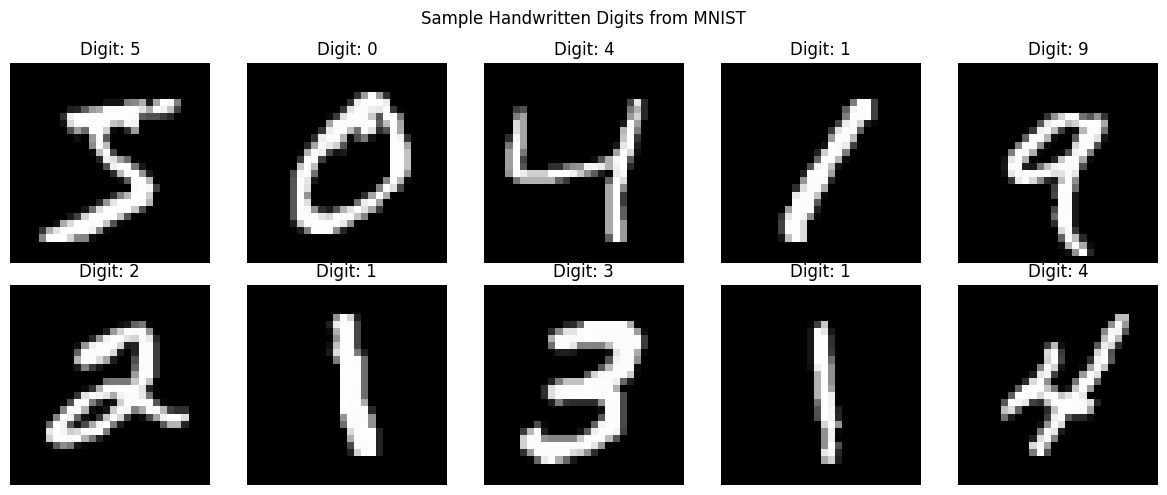

In [12]:
plt.figure(figsize=(12, 5))

for i in range(10):
    image = df.iloc[i, 1:].to_numpy(dtype='float32').reshape(28, 28)
    label = int(df.iloc[i]['label'])

    plt.subplot(2, 5, i + 1)
    plt.imshow(image, cmap='gray')
    plt.title(f"Digit: {label}")
    plt.axis('off')

plt.suptitle("Sample Handwritten Digits from MNIST")
plt.tight_layout()
plt.show()

### Separate features and labels

In [13]:
# Features: pixel values
X = df.drop('label', axis=1).to_numpy(dtype='float32')

# Target: actual digit
y = df['label'].to_numpy(dtype='int64')

print("Features shape:", X.shape)
print("Labels shape:", y.shape)

Features shape: (8035, 784)
Labels shape: (8035,)


### Normalize pixel values

In [14]:
X = X / 255.0

print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


### Split into training and testing sets

In [15]:
from sklearn.model_selection import train_test_split

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### Build the neural network

In [17]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

In [18]:
model = Sequential([
    Input(shape=(784,)),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Neural network architecture:
- Input: 784 pixel values
- Hidden layer 1: 128 neurons
- Dropout: 20%
- Hidden layer 2: 64 neurons
- Output: 10 neurons for digits 0–9

### Train the model

In [19]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.6648 - loss: 1.1699 - val_accuracy: 0.8725 - val_loss: 0.4431
Epoch 2/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8809 - loss: 0.4174 - val_accuracy: 0.9114 - val_loss: 0.3417
Epoch 3/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9122 - loss: 0.3093 - val_accuracy: 0.9176 - val_loss: 0.2816
Epoch 4/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9243 - loss: 0.2640 - val_accuracy: 0.9191 - val_loss: 0.2558
Epoch 5/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9366 - loss: 0.2257 - val_accuracy: 0.9253 - val_loss: 0.2395
Epoch 6/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9450 - loss: 0.1909 - val_accuracy: 0.9316 - val_loss: 0.2370
Epoch 7/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9514 - loss: 0.1707 - val_accuracy: 0.9238 - val_loss: 0.2363
Epoch 8/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9551 - loss: 0.1523 - val_accuracy: 0.9285 - val_loss

Explanation:
- epochs=10: the model goes through the training data ten times.
- batch_size=128: the model processes 128 images per batch.
- validation_split=0.1: 10% of the training portion is used to monitor validation performance.
- history: stores the accuracy and loss values for plotting.

### Plot the accuracy graph

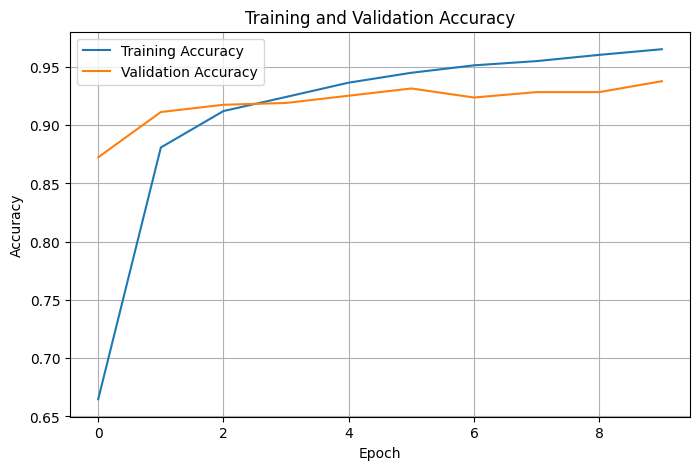

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

### Plot the loss graph

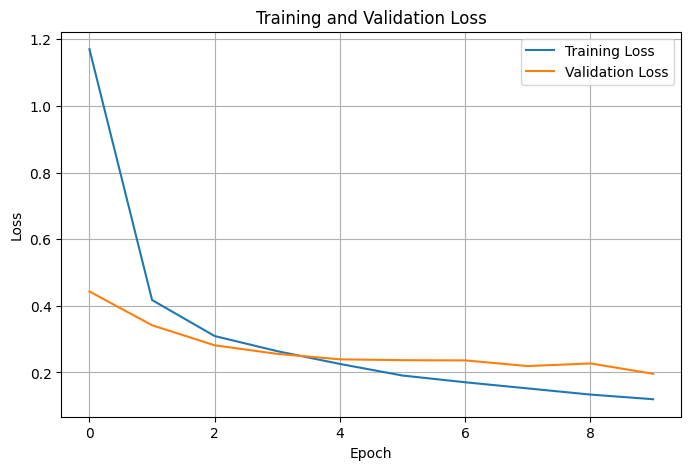

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

### Evaluate the model

In [22]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [23]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))

Test Accuracy: 94.34 %
Test Loss: 0.193


Generate predictions

In [24]:
# Predict probabilities for test images
y_prob = model.predict(X_test, verbose=0)

# Select the digit with the highest probability
y_pred = np.argmax(y_prob, axis=1)

print("First 10 actual digits:", y_test[:10])
print("First 10 predicted digits:", y_pred[:10])

First 10 actual digits: [2 0 6 6 9 0 9 4 8 3]
First 10 predicted digits: [2 0 2 6 9 0 9 4 3 3]


### Display prediction examples

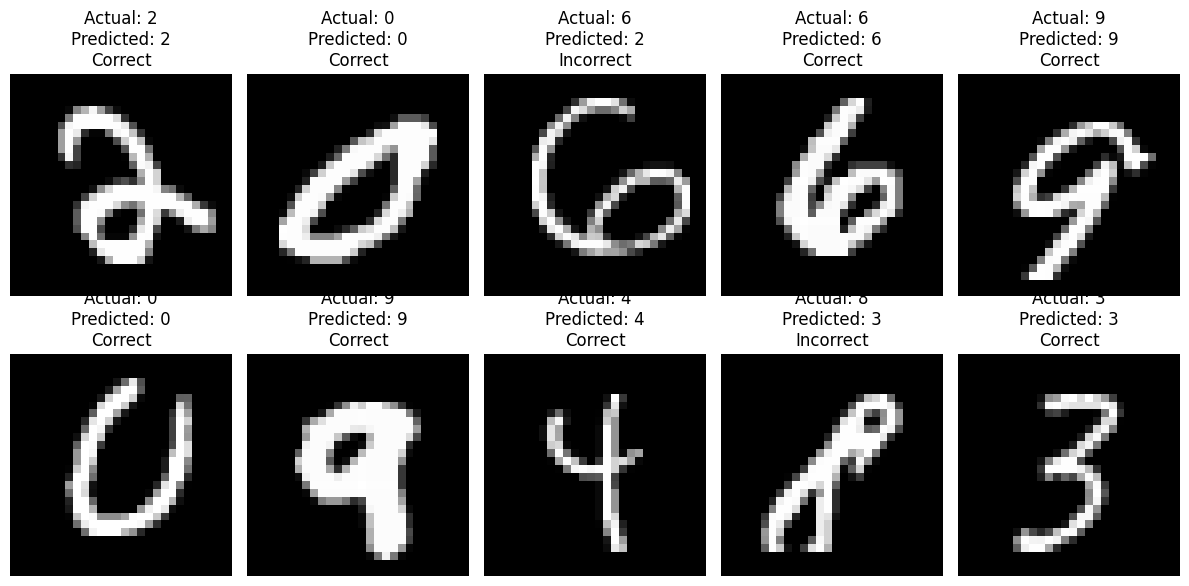

In [25]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')

    actual = y_test[i]
    predicted = y_pred[i]

    result = "Correct" if actual == predicted else "Incorrect"

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}\n{result}"
    )
    plt.axis('off')

plt.tight_layout()
plt.show()

Compare actual and predicted values in a table

In [26]:
results = pd.DataFrame({
    'Actual Digit': y_test[:10],
    'Predicted Digit': y_pred[:10]
})

results['Correct Prediction'] = (
    results['Actual Digit'] == results['Predicted Digit']
)

print(results)

   Actual Digit  Predicted Digit  Correct Prediction
0             2                2                True
1             0                0                True
2             6                2               False
3             6                6                True
4             9                9                True
5             0                0                True
6             9                9                True
7             4                4                True
8             8                3               False
9             3                3                True


Create the confusion matrix

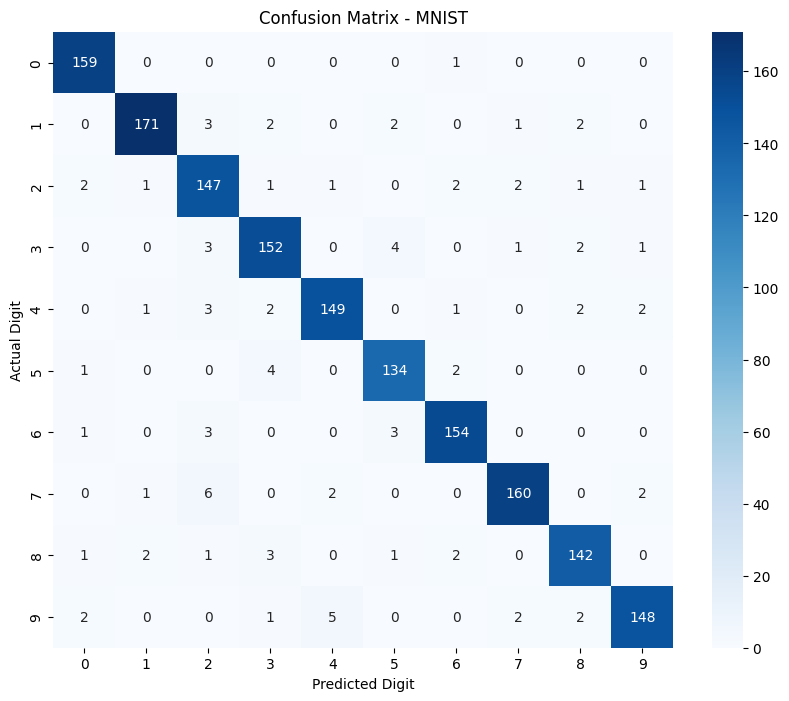

In [27]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title('Confusion Matrix - MNIST')
plt.xlabel('Predicted Digit')
plt.ylabel('Actual Digit')
plt.show()

Classification report

In [28]:
print(classification_report(y_test, y_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9578    0.9938    0.9755       160
           1     0.9716    0.9448    0.9580       181
           2     0.8855    0.9304    0.9074       158
           3     0.9212    0.9325    0.9268       163
           4     0.9490    0.9313    0.9401       160
           5     0.9306    0.9504    0.9404       141
           6     0.9506    0.9565    0.9536       161
           7     0.9639    0.9357    0.9496       171
           8     0.9404    0.9342    0.9373       152
           9     0.9610    0.9250    0.9427       160

    accuracy                         0.9434      1607
   macro avg     0.9432    0.9434    0.9431      1607
weighted avg     0.9439    0.9434    0.9434      1607



Analyze incorrect predictions

Total incorrect predictions: 91


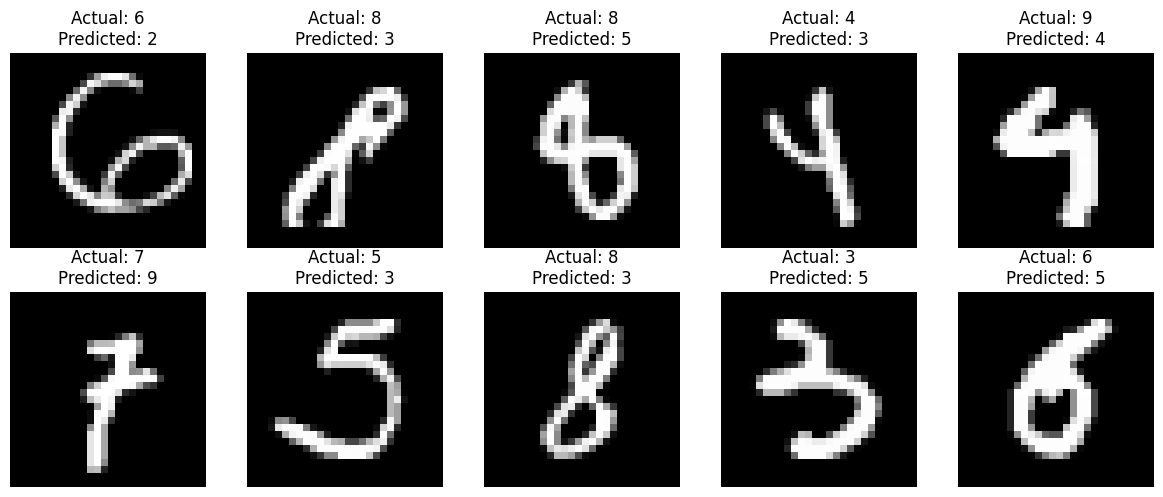

In [29]:
wrong_indices = np.where(y_test != y_pred)[0]

print("Total incorrect predictions:", len(wrong_indices))

plt.figure(figsize=(12, 5))

for i, index in enumerate(wrong_indices[:10]):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[index].reshape(28, 28), cmap='gray')

    plt.title(
        f"Actual: {y_test[index]}\nPredicted: {y_pred[index]}"
    )
    plt.axis('off')

plt.tight_layout()
plt.show()